In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score,classification_report

import matplotlib.pyplot as plt

In [ ]:
from google.colab import files
uploaded = files.upload()

import pandas as pd
df = pd.read_csv("student_pass_fail.csv")
df.head()

Saving student_pass_fail.csv to student_pass_fail (1).csv


,student_id,marks,attendance,study_hours,result
0,S001,56,71,3.3,Fail
1,S002,54,77,4.6,Pass
2,S003,60,73,4.0,Fail
3,S004,71,77,3.7,Pass
4,S005,61,79,4.6,Pass


In [ ]:
x=df[['study_hours','attendance','marks']]
y=df[['result']]

In [ ]:
print("input features")
print(x)
print("output features")
print(y)

input features
     study_hours  attendance  marks
0            3.3          71     56
1            4.6          77     54
2            4.0          73     60
3            3.7          77     71
4            4.6          79     61
..           ...         ...    ...
195          2.7          57     53
196          3.2          74     60
197          2.7          75     69
198          1.7          84     46
199          2.3          93     56

[200 rows x 3 columns]
output features
    result
0     Fail
1     Pass
2     Fail
3     Pass
4     Pass
..     ...
195   Fail
196   Fail
197   Pass
198   Pass
199   Pass

[200 rows x 1 columns]


In [ ]:
x_tr,x_te,y_tr,y_te=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
print("Traning record:",len(x_tr))
print("Testing record:",len(x_te))

Traning record: 160
Testing record: 40


In [ ]:
tree_clf.fit(x_tr,y_tr)
print("Decision tree model trained succesfully")

Decision tree model trained succesfully


In [ ]:
y_pred=tree_clf.predict(x_te)
comparison=pd.DataFrame({
    "Actual Result":y_te.values,
    "Predicted Result":y_pred
    })
display(comparison)

,Actual Result,Predicted Result
0,Fail,Fail
1,Fail,Fail
2,Fail,Fail
3,Fail,Fail
4,Pass,Pass
5,Pass,Pass
6,Pass,Pass
7,Pass,Pass
8,Pass,Pass
9,Pass,Pass


In [ ]:
display("tested",len(y_te))
display("predicted",len(y_pred))

'tested'

40

'predicted'

40

In [ ]:
print("Accuracy:",round(accuracy_score(y_te,y_pred),3))
print("\nClassification Report:")
print(classification_report(y_te,y_pred,zero_division=0))

Accuracy: 0.975

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      0.95      0.98        22
        Pass       0.95      1.00      0.97        18

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40



[Text(0.5, 0.75, 'attendance <= 74.5\ngini = 0.494\nsamples = 160\nvalue = [89, 71]\nclass = Fail'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 89\nvalue = [89, 0]\nclass = Fail'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 71\nvalue = [0, 71]\nclass = Pass'),
 Text(0.625, 0.5, '  False')]

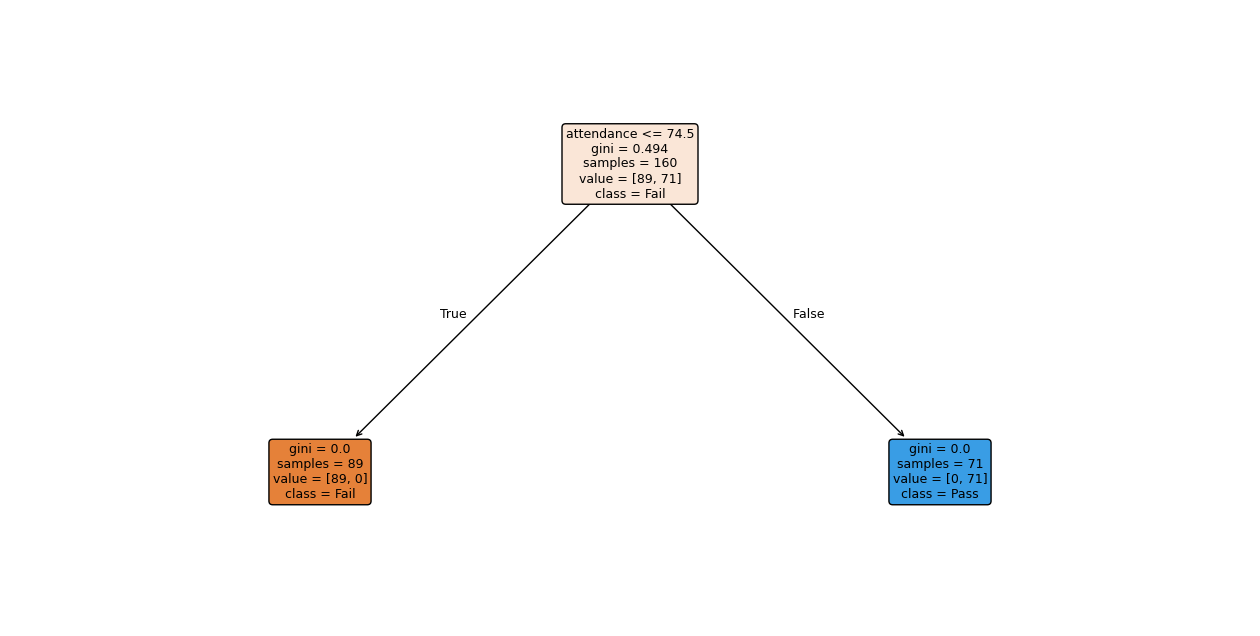

In [ ]:
plt.figure(figsize=(16,8))
plot_tree(
    tree_clf,
    feature_names=x.columns,
    class_names=["Fail","Pass"],
    filled=True,
    rounded=True,
    fontsize=9
)